<a href="https://colab.research.google.com/github/harrisariefkamis/PROJECT-DATA-SCIENTIST/blob/main/pratice_analisis_dasar_data_scientist_ml_komdigi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktik Analisis Data dan Machine Learning

Notebook ini mendemonstrasikan inspeksi, visualisasi, pemeriksaan kualitas, pembagian data, dan klasifikasi dataset Iris.

## Bab 1: Muat dan Inspeksi Dataset Iris

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

iris = load_iris()
FEATURE_COLUMNS = list(iris.feature_names)
TARGET_COLUMN = "target"

# Buat satu DataFrame utama untuk seluruh analisis.
df = pd.DataFrame(iris.data, columns=FEATURE_COLUMNS)
df[TARGET_COLUMN] = iris.target
df["species"] = pd.Categorical.from_codes(
    iris.target,
    categories=iris.target_names,
)

print("=== Ringkasan dataset Iris ===")
print(f"Ukuran data: {df.shape[0]} baris x {df.shape[1]} kolom")
print("\nTipe data dan jumlah nilai non-null:")
df.info()
print("\nLima baris pertama:")
print(df.head().to_string(index=False))
print("\nStatistik deskriptif fitur:")
print(df[FEATURE_COLUMNS].describe().T.round(2))
print("\nJumlah observasi per spesies:")
print(df["species"].value_counts().sort_index())
print("\nKorelasi antarfitur:")
print(df[FEATURE_COLUMNS].corr().round(2))

=== Ringkasan dataset Iris ===
Ukuran data: 150 baris x 6 kolom

Tipe data dan jumlah nilai non-null:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   target             150 non-null    int64   
 5   species            150 non-null    category
dtypes: category(1), float64(4), int64(1)
memory usage: 6.2 KB

Lima baris pertama:
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target species
               5.1               3.5                1.4               0.2       0  setosa
               4.9               3.0                1.4               0.2       0  setosa
               4.7               3.2                1.3    

## Bab 2: Visualisasi Data

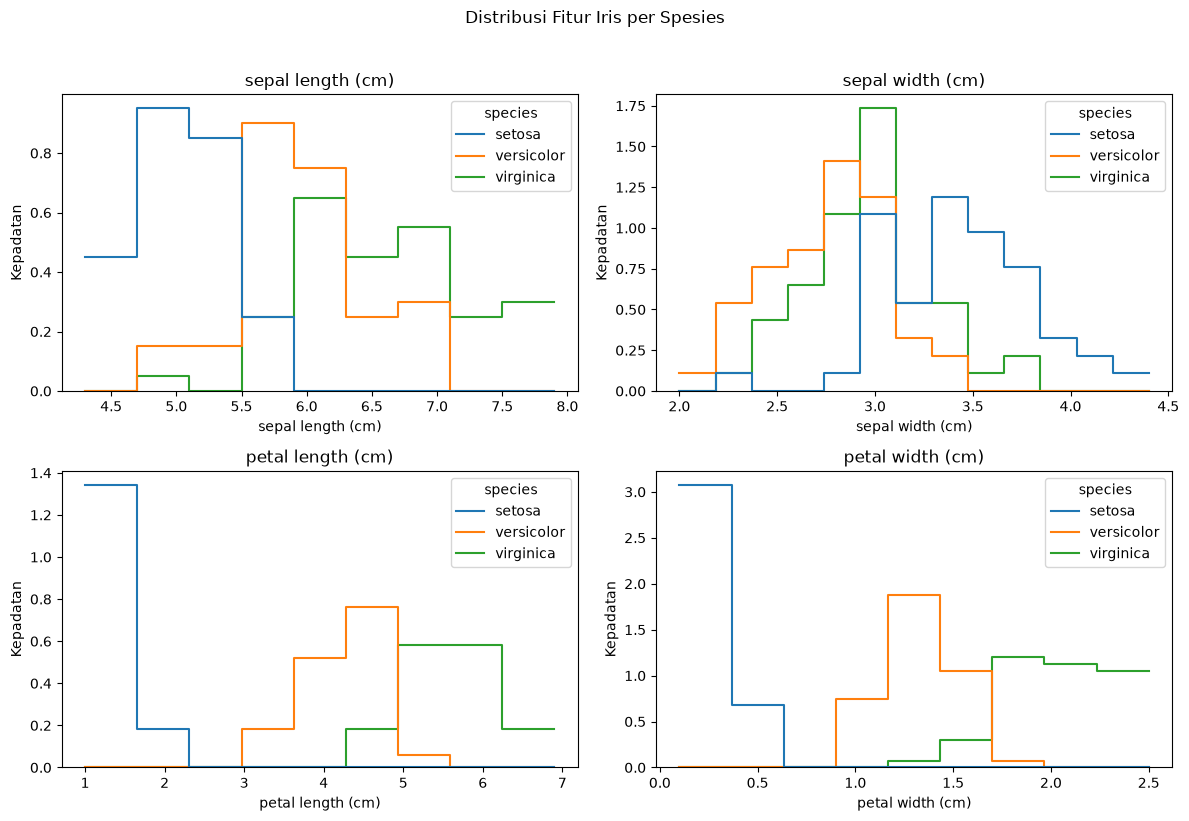

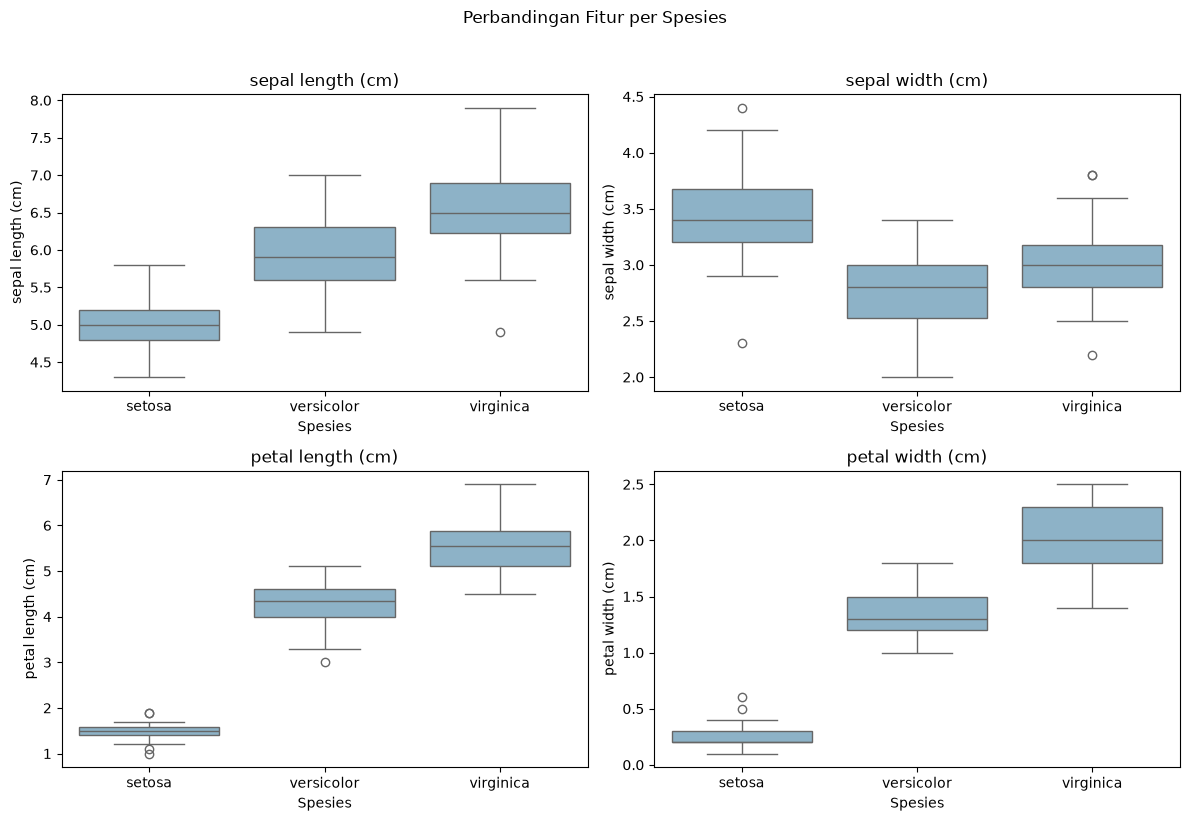

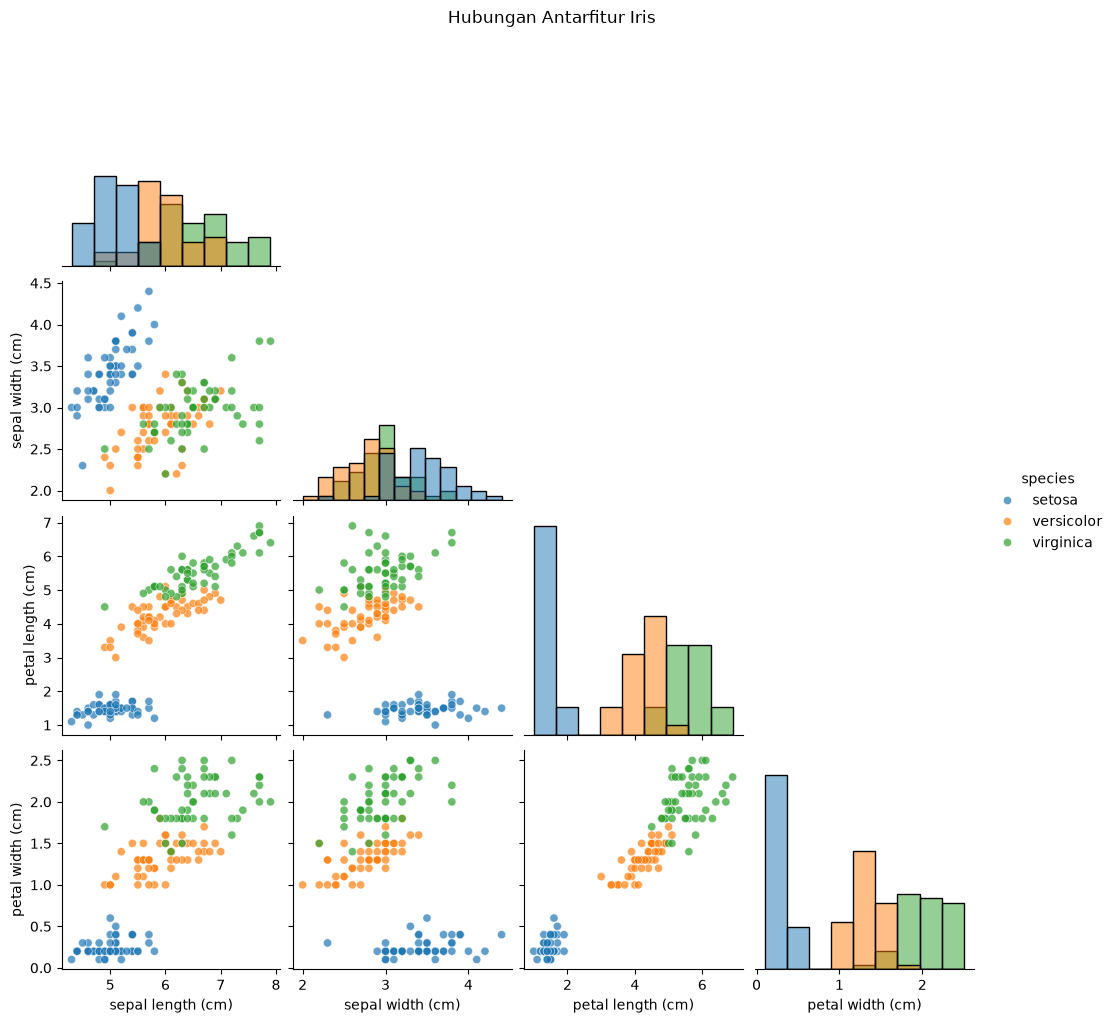

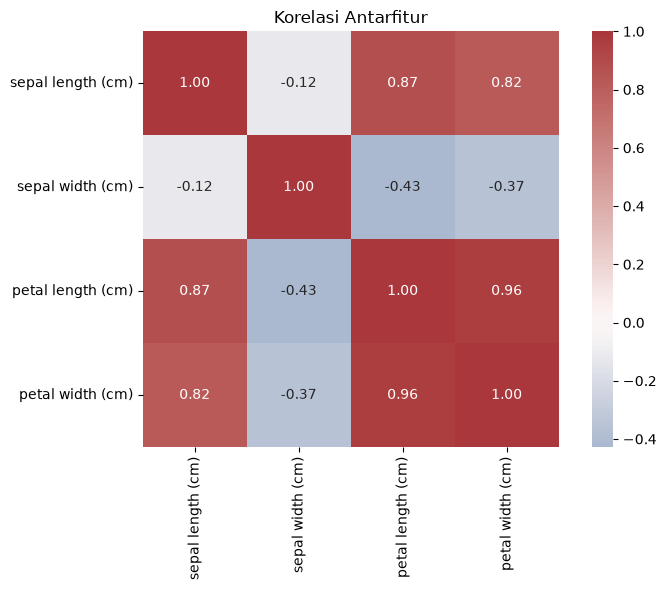

In [11]:
# Distribusi setiap fitur berdasarkan spesies.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, feature in zip(axes.flat, FEATURE_COLUMNS):
    sns.histplot(
        data=df,
        x=feature,
        hue="species",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axis,
    )
    axis.set_title(feature)
    axis.set_ylabel("Kepadatan")
fig.suptitle("Distribusi Fitur Iris per Spesies", y=1.02)
fig.tight_layout()
plt.show()

# Bandingkan rentang dan pencilan tiap fitur antarspesies.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, feature in zip(axes.flat, FEATURE_COLUMNS):
    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        order=iris.target_names,
        color="#83B5D1",
        ax=axis,
    )
    axis.set_title(feature)
    axis.set_xlabel("Spesies")
fig.suptitle("Perbandingan Fitur per Spesies", y=1.02)
fig.tight_layout()
plt.show()

# Hubungan berpasangan antarfitur numerik.
pair_plot = sns.pairplot(
    data=df,
    vars=FEATURE_COLUMNS,
    hue="species",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 35},
)
pair_plot.fig.suptitle("Hubungan Antarfitur Iris", y=1.02)
plt.show()

# Korelasi hanya dihitung pada fitur numerik, bukan label kelas.
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    df[FEATURE_COLUMNS].corr(),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
    ax=ax,
)
ax.set_title("Korelasi Antarfitur")
fig.tight_layout()
plt.show()

## Bab 3: Pemeriksaan Kualitas Data

In [12]:
# Ringkasan kelengkapan dan keunikan setiap kolom.
quality_summary = pd.DataFrame(
    {
        "Tipe data": df.dtypes.astype(str),
        "Nilai kosong": df.isna().sum(),
        "Nilai unik": df.nunique(),
    }
)
print("=== Pemeriksaan kualitas data ===")
print(quality_summary.to_string())

# Deteksi baris duplikat tanpa mengubah dataset sumber.
duplicate_count = int(df.duplicated().sum())
print(f"\nJumlah baris duplikat: {duplicate_count}")

# Validasi domain dasar: seluruh pengukuran Iris harus bernilai positif.
invalid_measurements = df.loc[
    (df[FEATURE_COLUMNS] <= 0).any(axis=1),
    FEATURE_COLUMNS + ["species"],
]
print(f"Baris dengan pengukuran nonpositif: {len(invalid_measurements)}")
if not invalid_measurements.empty:
    print(invalid_measurements.to_string(index=False))

# Pastikan kode target sesuai dengan label spesiesnya.
expected_species = df[TARGET_COLUMN].map(dict(enumerate(iris.target_names)))
inconsistent_labels = df.loc[
    df["species"].astype(str).ne(expected_species),
    [TARGET_COLUMN, "species"],
]
print(f"Label spesies yang tidak konsisten: {len(inconsistent_labels)}")
if not inconsistent_labels.empty:
    print(inconsistent_labels.to_string(index=False))

=== Pemeriksaan kualitas data ===
                  Tipe data  Nilai kosong  Nilai unik
sepal length (cm)   float64             0          35
sepal width (cm)    float64             0          23
petal length (cm)   float64             0          43
petal width (cm)    float64             0          22
target                int64             0           3
species            category             0           3

Jumlah baris duplikat: 1
Baris dengan pengukuran nonpositif: 0
Label spesies yang tidak konsisten: 0


## Bab 4: Deteksi Outlier dengan IQR

In [13]:
# Deteksi outlier dengan batas IQR per fitur; data sumber tidak diubah.
outlier_masks = pd.DataFrame(False, index=df.index, columns=FEATURE_COLUMNS)
outlier_bounds = []

for feature in FEATURE_COLUMNS:
    first_quartile = df[feature].quantile(0.25)
    third_quartile = df[feature].quantile(0.75)
    interquartile_range = third_quartile - first_quartile
    lower_bound = first_quartile - 1.5 * interquartile_range
    upper_bound = third_quartile + 1.5 * interquartile_range

    outlier_masks[feature] = df[feature].lt(lower_bound) | df[feature].gt(upper_bound)
    outlier_bounds.append(
        {
            "Fitur": feature,
            "Batas bawah": lower_bound,
            "Batas atas": upper_bound,
            "Jumlah outlier": int(outlier_masks[feature].sum()),
        }
    )

outlier_summary = pd.DataFrame(outlier_bounds).set_index("Fitur")
outlier_rows = df.loc[
    outlier_masks.any(axis=1),
    FEATURE_COLUMNS + ["species"],
]

print("=== Deteksi outlier menggunakan IQR ===")
print(outlier_summary.round(2).to_string())
print(f"\nJumlah baris dengan minimal satu outlier: {len(outlier_rows)}")
if not outlier_rows.empty:
    print(outlier_rows.to_string(index=False))
print("\nOutlier ditandai untuk ditinjau, tidak dihapus otomatis.")

=== Deteksi outlier menggunakan IQR ===
                   Batas bawah  Batas atas  Jumlah outlier
Fitur                                                     
sepal length (cm)         3.15        8.35               0
sepal width (cm)          2.05        4.05               4
petal length (cm)        -3.65       10.35               0
petal width (cm)         -1.95        4.05               0

Jumlah baris dengan minimal satu outlier: 4
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)    species
               5.7               4.4                1.5               0.4     setosa
               5.2               4.1                1.5               0.1     setosa
               5.5               4.2                1.4               0.2     setosa
               5.0               2.0                3.5               1.0 versicolor

Outlier ditandai untuk ditinjau, tidak dihapus otomatis.


## Bab 5: Pembagian Data Train dan Test

In [14]:
# Pisahkan fitur dan target sebelum membagi data.
X = df.loc[:, FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

class_distribution = pd.DataFrame(
    {
        "Train": y_train.value_counts().sort_index().to_numpy(),
        "Test": y_test.value_counts().sort_index().to_numpy(),
    },
    index=pd.Index(iris.target_names, name="Spesies"),
)

print("=== Pembagian data ===")
print(f"Ukuran fitur train: {X_train.shape}")
print(f"Ukuran fitur test: {X_test.shape}")
print("\nDistribusi kelas per subset:")
print(class_distribution.to_string())

=== Pembagian data ===
Ukuran fitur train: (120, 4)
Ukuran fitur test: (30, 4)

Distribusi kelas per subset:
            Train  Test
Spesies                
setosa         40    10
versicolor     40    10
virginica      40    10


## Bab 6: Seleksi Fitur dan Baris

In [15]:
SELECTED_FEATURES = [FEATURE_COLUMNS[0], FEATURE_COLUMNS[2]]

print("=== Seleksi baris dan fitur ===")
print(f"Jumlah baris train: {len(X_train)}")
print(f"Jumlah baris test: {len(X_test)}")

print("\nLima baris train pertama:")
print(X_train.iloc[:5].to_string())

print(f"\nLima baris train untuk fitur {SELECTED_FEATURES}:")
print(X_train.loc[:, SELECTED_FEATURES].iloc[:5].to_string())

sample_labels = y_train.loc[X_train.index[:5]].map(
    dict(enumerate(iris.target_names))
)
print("\nLabel spesies untuk lima baris train pertama:")
print(sample_labels.to_string())

=== Seleksi baris dan fitur ===
Jumlah baris train: 120
Jumlah baris test: 30

Lima baris train pertama:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
8                  4.4               2.9                1.4               0.2
106                4.9               2.5                4.5               1.7
76                 6.8               2.8                4.8               1.4
9                  4.9               3.1                1.5               0.1
89                 5.5               2.5                4.0               1.3

Lima baris train untuk fitur ['sepal length (cm)', 'petal length (cm)']:
     sepal length (cm)  petal length (cm)
8                  4.4                1.4
106                4.9                4.5
76                 6.8                4.8
9                  4.9                1.5
89                 5.5                4.0

Label spesies untuk lima baris train pertama:
8          setosa
106     virginica
76     versicolor


## Bab 7: Pelatihan dan Evaluasi Model

=== Evaluasi model pada test set ===
Akurasi: 0.933

Classification report:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



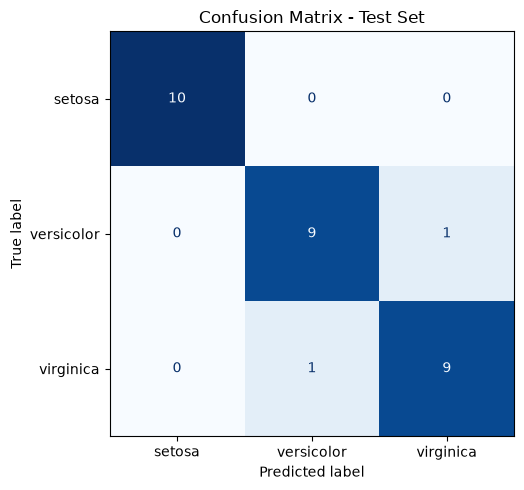

In [16]:
# Standardisasi dipasang di dalam pipeline agar parameter hanya dipelajari dari train set.
classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1_000, random_state=42),
)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print("=== Evaluasi model pada test set ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0,
        digits=3,
    )
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Confusion Matrix - Test Set")
fig.tight_layout()
plt.show()